# GPU LSTM Training — Atlanta and Birmingham

This notebook trains the complete controlled experiment: **Baseline 0, Model A, Model B, Model C, and Model D** for both cities.

The same LSTM architecture and training protocol are used for Models A–D. Only the feature set changes. The 2023 test period remains untouched until final evaluation.

Expected project structure:

```text
LSTM_GPU_TRAINING/
└── LSTM_DATA_PREP/
    ├── data/
    │   ├── atlanta_master.csv
    │   └── birmingham_master.csv
    └── prepared_lstm/
        ├── atlanta/
        └── birmingham/
```

The notebook consumes the prepared artifacts already created by the data preparation notebooks and does not rebuild preprocessing.


In [2]:
import numpy as np
import sklearn
import tensorflow as tf

print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 1.26.4
Scikit-learn: 1.7.2
TensorFlow: 2.10.0


## 1. Configuration


In [3]:
from __future__ import annotations

import gc
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib


In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
PREPARED_DIR = PROJECT_DIR / "prepared_lstm"
RESULTS_DIR = PROJECT_DIR / "training_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CITIES = ["Atlanta", "Birmingham"]

HORIZON_HOURS = 1
LOOKBACK_HOURS = 168
BATCH_SIZE = 64
MAX_EPOCHS = 100

LEARNING_RATE = 1e-3
L2_REG = 1e-4
DROPOUT = 0.25
EARLY_STOPPING_PATIENCE = 10
LR_PATIENCE = 4
LR_FACTOR = 0.5
MIN_LR = 1e-6
HUBER_DELTA = 1.0

VALIDATION_START = pd.Timestamp("2022-01-01 00:00:00")
TEST_START = pd.Timestamp("2023-01-01 00:00:00")

MODEL_NAMES = ["Model_A", "Model_B", "Model_C", "Model_D"]

print("Project:", PROJECT_DIR.resolve())
print("Prepared:", PREPARED_DIR.resolve())
print("Results:", RESULTS_DIR.resolve())


Project: D:\Downloads\BTP\model_training\lstm_training_2\LSTM_GPU_TRAINING\LSTM_DATA_PREP
Prepared: D:\Downloads\BTP\model_training\lstm_training_2\LSTM_GPU_TRAINING\LSTM_DATA_PREP\prepared_lstm
Results: D:\Downloads\BTP\model_training\lstm_training_2\LSTM_GPU_TRAINING\LSTM_DATA_PREP\training_results


## 2. Verify TensorFlow and GPU

Training is intended to run on the RTX 3050 GPU. If no GPU is detected, stop here and fix the TensorFlow/CUDA environment before training.


In [5]:
print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
GPUS = tf.config.list_physical_devices("GPU")
print("Visible GPUs:", GPUS)

if not GPUS:
    raise RuntimeError(
        "No TensorFlow GPU was detected. Stop here and fix the CUDA/TensorFlow environment before training."
    )

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("GPU training is available.")


TensorFlow version: 2.10.0
Built with CUDA: True
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU training is available.


## 3. Load prepared artifacts and feature definitions


In [6]:
city_data = {}

for city in CITIES:
    city_dir = PREPARED_DIR / city.lower()

    required = [
        "features_scaled.npy",
        "target_scaled.npy",
        "split_codes.npy",
        "row_index.csv",
        "transformers.joblib",
        "metadata.json",
        "feature_groups.json",
        "features_model_d_scaled.npy",
    ]

    missing = [f for f in required if not (city_dir / f).exists()]
    if missing:
        raise FileNotFoundError(f"{city}: missing prepared artifacts: {missing}")

    metadata = json.loads((city_dir / "metadata.json").read_text(encoding="utf-8"))
    groups = json.loads((city_dir / "feature_groups.json").read_text(encoding="utf-8"))
    rows = pd.read_csv(
        city_dir / "row_index.csv",
        parse_dates=["timestamp", "target_timestamp"]
    )
    transformers = joblib.load(city_dir / "transformers.joblib")

    city_data[city] = {
        "dir": city_dir,
        "metadata": metadata,
        "groups": groups,
        "rows": rows,
        "transformers": transformers,
        "feature_names": metadata["feature_names"],
    }

    print(f"{city}: rows={len(rows)}, Model A={groups['model_a_feature_count']}, "
          f"Model B={groups['model_b_feature_count']}, "
          f"Model C={groups['model_c_feature_count']}, "
          f"Model D={groups['model_d_feature_count']}")


Atlanta: rows=69911, Model A=31, Model B=43, Model C=44, Model D=51
Birmingham: rows=69911, Model A=31, Model B=43, Model C=44, Model D=51


In [7]:
BASE_FEATURES = city_data["Atlanta"]["feature_names"]

assert BASE_FEATURES == city_data["Birmingham"]["feature_names"]
assert city_data["Atlanta"]["groups"]["model_c_feature_count"] == 44
assert city_data["Birmingham"]["groups"]["model_c_feature_count"] == 44
assert city_data["Atlanta"]["groups"]["model_d_feature_count"] == 51
assert city_data["Birmingham"]["groups"]["model_d_feature_count"] == 51
assert LOOKBACK_HOURS == city_data["Atlanta"]["metadata"]["lookback_hours"]
assert LOOKBACK_HOURS == city_data["Birmingham"]["metadata"]["lookback_hours"]

print("Prepared feature contracts verified.")


Prepared feature contracts verified.


## 4. Streamed LSTM sequence loader

The full `(samples, 168, features)` tensor is never materialized. Each batch is assembled from memory-mapped `.npy` files immediately before it is passed to the GPU.

Split codes are `0=train`, `1=validation`, `2=test`.


In [8]:
class LSTMWindowSequence(tf.keras.utils.Sequence):
    def __init__(
        self,
        city_dir,
        split,
        feature_source,
        feature_indices=None,
        lookback=168,
        batch_size=64,
        shuffle=False,
    ):
        super().__init__()
        self.city_dir = Path(city_dir)
        self.split = split
        self.lookback = lookback
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.feature_indices = feature_indices

        self.X = np.load(self.city_dir / feature_source, mmap_mode="r")
        self.y = np.load(self.city_dir / "target_scaled.npy", mmap_mode="r")
        self.codes = np.load(self.city_dir / "split_codes.npy", mmap_mode="r")

        code = {"train": 0, "validation": 1, "test": 2}[split]
        self.end_indices = np.flatnonzero(self.codes == code)
        self.end_indices = self.end_indices[self.end_indices >= lookback - 1]

        self.order = np.arange(len(self.end_indices))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.end_indices) / self.batch_size))

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        end = min(start + self.batch_size, len(self.end_indices))
        selected = self.end_indices[self.order[start:end]]

        if len(selected) == 0:
            raise IndexError(f"Empty batch {batch_index}.")

        xb = np.stack([
            self.X[i - self.lookback + 1:i + 1]
            for i in selected
        ]).astype(np.float32, copy=False)

        if self.feature_indices is not None:
            xb = xb[:, :, self.feature_indices]

        yb = np.asarray(self.y[selected], dtype=np.float32)
        return xb, yb

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)


## 5. Fixed LSTM architecture

```text
Input (168 × features)
        ↓
LSTM 64 + L2(1e-4)
        ↓
Dropout 0.25
        ↓
LSTM 32 + L2(1e-4)
        ↓
Dropout 0.25
        ↓
Dense 16 ReLU + L2(1e-4)
        ↓
Dense 1 Linear
```

The architecture is identical for Models A–D.


In [9]:
def build_lstm(n_features: int) -> tf.keras.Model:
    reg = tf.keras.regularizers.l2(L2_REG)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK_HOURS, n_features)),
        tf.keras.layers.LSTM(
            64,
            return_sequences=True,
            kernel_regularizer=reg,
        ),
        tf.keras.layers.Dropout(DROPOUT),
        tf.keras.layers.LSTM(
            32,
            return_sequences=False,
            kernel_regularizer=reg,
        ),
        tf.keras.layers.Dropout(DROPOUT),
        tf.keras.layers.Dense(
            16,
            activation="relu",
            kernel_regularizer=reg,
        ),
        tf.keras.layers.Dense(1, activation="linear"),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=tf.keras.losses.Huber(delta=HUBER_DELTA),
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")],
    )

    return model


## 6. Model feature mapping


In [11]:
MODEL_FEATURES = {
    "Model_A": city_data["Atlanta"]["groups"]["model_a"]["features"],
    "Model_B": city_data["Atlanta"]["groups"]["model_b"]["features"],
    "Model_C": city_data["Atlanta"]["groups"]["model_c"]["features"],
    "Model_D": city_data["Atlanta"]["groups"]["model_d"]["features"],
}

MODEL_SOURCES = {
    "Model_A": "features_scaled.npy",
    "Model_B": "features_scaled.npy",
    "Model_C": "features_scaled.npy",
    "Model_D": "features_model_d_scaled.npy",
}

# Models A, B and C are subsets of the 45-feature base matrix.
MODEL_INDICES = {
    model: [BASE_FEATURES.index(feature) for feature in features]
    for model, features in MODEL_FEATURES.items()
    if model != "Model_D"
}

print("Feature counts:")
print({
    model: len(features)
    for model, features in MODEL_FEATURES.items()
})

print("\nBase feature indices:")
print({
    model: len(indices)
    for model, indices in MODEL_INDICES.items()
})

Feature counts:
{'Model_A': 31, 'Model_B': 43, 'Model_C': 44, 'Model_D': 51}

Base feature indices:
{'Model_A': 31, 'Model_B': 43, 'Model_C': 44}


## 7. Training helper

Early stopping monitors validation loss and restores the best validation weights. ReduceLROnPlateau changes the learning rate using validation data only. The test set is not used by callbacks.


In [12]:
def train_model(city: str, model_name: str):
    city_dir = city_data[city]["dir"]
    source = MODEL_SOURCES[model_name]

    if model_name == "Model_D":
        n_features = 51
        feature_indices = None
    else:
        feature_indices = MODEL_INDICES[model_name]
        n_features = len(feature_indices)

    train_seq = LSTMWindowSequence(
        city_dir,
        "train",
        source,
        feature_indices=feature_indices,
        lookback=LOOKBACK_HOURS,
        batch_size=BATCH_SIZE,
        shuffle=True,
    )

    val_seq = LSTMWindowSequence(
        city_dir,
        "validation",
        source,
        feature_indices=feature_indices,
        lookback=LOOKBACK_HOURS,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    test_seq = LSTMWindowSequence(
        city_dir,
        "test",
        source,
        feature_indices=feature_indices,
        lookback=LOOKBACK_HOURS,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    model = build_lstm(n_features)

    model_dir = RESULTS_DIR / city.lower() / model_name.lower()
    model_dir.mkdir(parents=True, exist_ok=True)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=LR_FACTOR,
            patience=LR_PATIENCE,
            min_lr=MIN_LR,
            verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            model_dir / "training_history.csv"
        ),
    ]

    print(f"\n{city} — {model_name}")
    print("Features:", n_features)
    print("Train windows:", len(train_seq.end_indices))
    print("Validation windows:", len(val_seq.end_indices))
    print("Test windows:", len(test_seq.end_indices))

    model.summary()

    history = model.fit(
        train_seq,
        validation_data=val_seq,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

    model.save(model_dir / "model.keras")
    pd.DataFrame(history.history).to_csv(
        model_dir / "history.csv",
        index=False,
    )

    return model, history, train_seq, val_seq, test_seq


## 8. Evaluation helpers


In [13]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    error = y_true - y_pred
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    ss_res = np.sum(error ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot != 0 else np.nan

    nonzero = np.abs(y_true) > 1e-8
    mape = (
        np.mean(np.abs(error[nonzero] / y_true[nonzero])) * 100
        if np.any(nonzero)
        else np.nan
    )

    denominator = np.sum(np.abs(y_true))
    wape = (
        np.sum(np.abs(error)) / denominator * 100
        if denominator != 0
        else np.nan
    )

    return {
        "R2": r2,
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "MAPE_percent": mape,
        "WAPE_percent": wape,
    }


def inverse_target(city, values):
    scaler = city_data[city]["transformers"]["target_scaler"]
    values = np.asarray(values).reshape(-1, 1)
    return scaler.inverse_transform(values).ravel()


def collect_predictions(model, sequence, city):
    pred_scaled = model.predict(sequence, verbose=0).ravel()

    y_scaled = np.concatenate([
        sequence[i][1]
        for i in range(len(sequence))
    ])

    y_pred = inverse_target(city, pred_scaled)
    y_true = inverse_target(city, y_scaled)

    return y_true, y_pred


## 9. Baseline 0 — historical hour × weekday schedule

This baseline is fitted only on 2016–2021. For each target timestamp it predicts the mean training load for that weekday and hour. It is not an LSTM.


In [14]:
def run_baseline_0(city: str):
    rows = city_data[city]["rows"].copy()
    city_dir = city_data[city]["dir"]

    target_scaler = city_data[city]["transformers"]["target_scaler"]
    y_scaled = np.load(
        city_dir / "target_scaled.npy",
        mmap_mode="r",
    )
    codes = np.load(
        city_dir / "split_codes.npy",
        mmap_mode="r",
    )

    rows["target_load_mw"] = target_scaler.inverse_transform(
        np.asarray(y_scaled).reshape(-1, 1)
    ).ravel()

    rows["target_hour"] = rows["target_timestamp"].dt.hour
    rows["target_dow"] = rows["target_timestamp"].dt.dayofweek
    rows["split_code"] = codes

    train = rows[rows["split_code"] == 0].copy()
    validation = rows[rows["split_code"] == 1].copy()
    test = rows[rows["split_code"] == 2].copy()

    lookup = train.groupby(
        ["target_dow", "target_hour"]
    )["target_load_mw"].mean()

    fallback = train["target_load_mw"].mean()

    def predict(frame):
        return np.asarray([
            lookup.get(
                (dow, hour),
                fallback,
            )
            for dow, hour in zip(
                frame["target_dow"],
                frame["target_hour"],
            )
        ])

    output_dir = RESULTS_DIR / city.lower() / "baseline_0"
    output_dir.mkdir(parents=True, exist_ok=True)

    results = []

    for split_name, frame in [
        ("validation", validation),
        ("test", test),
    ]:
        y_true = frame["target_load_mw"].to_numpy()
        y_pred = predict(frame)

        metrics = regression_metrics(y_true, y_pred)
        metrics.update({
            "City": city,
            "Model": "Baseline_0",
            "Split": split_name,
        })
        results.append(metrics)

        pd.DataFrame({
            "target_timestamp": frame["target_timestamp"].to_numpy(),
            "actual_load_mw": y_true,
            "predicted_load_mw": y_pred,
        }).to_csv(
            output_dir / f"{split_name}_predictions.csv",
            index=False,
        )

    metrics_df = pd.DataFrame(results)
    metrics_df.to_csv(
        output_dir / "metrics.csv",
        index=False,
    )

    return metrics_df


## 10. Train all models

This cell runs Baseline 0 plus Models A–D for Atlanta and Birmingham.

Because the models are trained sequentially and the RTX 3050 has limited VRAM, the TensorFlow session is cleared between LSTM experiments.


In [15]:
all_metrics = []
trained_models = {}

for city in CITIES:
    baseline_metrics = run_baseline_0(city)
    all_metrics.append(baseline_metrics)

    for model_name in MODEL_NAMES:
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED)

        model, history, train_seq, val_seq, test_seq = train_model(
            city,
            model_name,
        )

        trained_models[(city, model_name)] = model

        for split_name, sequence in [
            ("validation", val_seq),
            ("test", test_seq),
        ]:
            y_true, y_pred = collect_predictions(
                model,
                sequence,
                city,
            )

            metrics = regression_metrics(
                y_true,
                y_pred,
            )
            metrics.update({
                "City": city,
                "Model": model_name,
                "Split": split_name,
            })
            all_metrics.append(
                pd.DataFrame([metrics])
            )

            output_dir = (
                RESULTS_DIR
                / city.lower()
                / model_name.lower()
            )

            timestamps = city_data[city]["rows"].loc[
                sequence.end_indices,
                "target_timestamp",
            ].to_numpy()

            pd.DataFrame({
                "target_timestamp": timestamps,
                "actual_load_mw": y_true,
                "predicted_load_mw": y_pred,
            }).to_csv(
                output_dir / f"{split_name}_predictions.csv",
                index=False,
            )

        del model, history, train_seq, val_seq, test_seq
        gc.collect()

metrics_table = pd.concat(
    all_metrics,
    ignore_index=True,
)

metrics_table.to_csv(
    RESULTS_DIR / "all_model_metrics.csv",
    index=False,
)

display(metrics_table)



Atlanta — Model_A
Features: 31
Train windows: 52224
Validation windows: 8760
Test windows: 8760
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 168, 64)           24576     
                                                                 
 dropout (Dropout)           (None, 168, 64)           0         
                                                                 
 lstm_1 (LSTM)               (None, 32)                12416     
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 dense (Dense)               (None, 16)                528       
                                                                 
 dense_1 (Dense)             (None, 1)                 17        
                         

,R2,MAE_MW,RMSE_MW,MAPE_percent,WAPE_percent,City,Model,Split
0,0.196949,239.782261,303.993701,13.916379,14.697665,Atlanta,Baseline_0,validation
1,0.267117,219.142828,278.740639,13.097927,13.784746,Atlanta,Baseline_0,test
2,0.457113,179.099764,249.946983,10.314910,10.978078,Atlanta,Model_A,validation
3,0.694690,131.663606,179.909179,8.099629,8.282039,Atlanta,Model_A,test
4,0.978954,35.382624,49.213012,2.044304,2.168809,Atlanta,Model_B,validation
5,0.981283,32.541016,44.545689,1.953273,2.046928,Atlanta,Model_B,test
6,0.981173,33.988034,46.546706,2.049848,2.083327,Atlanta,Model_C,validation
7,0.981303,33.303224,44.521722,2.067216,2.094873,Atlanta,Model_C,test
8,0.984587,31.895592,42.115534,1.906184,1.955068,Atlanta,Model_D,validation
9,0.986639,29.087891,37.635212,1.819388,1.829716,Atlanta,Model_D,test


## 11. Learning curves


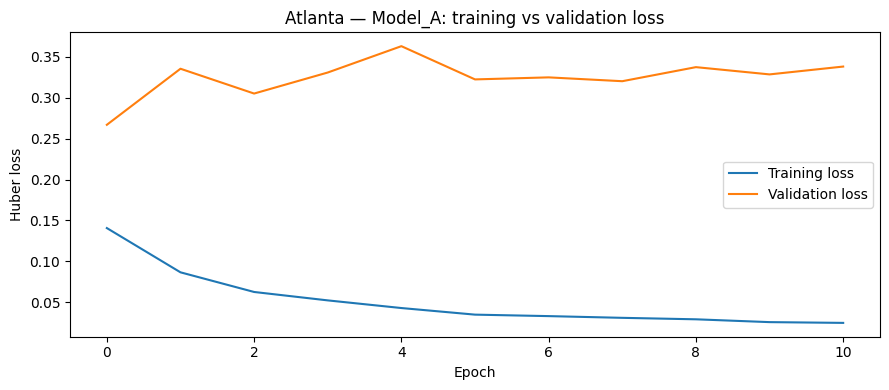

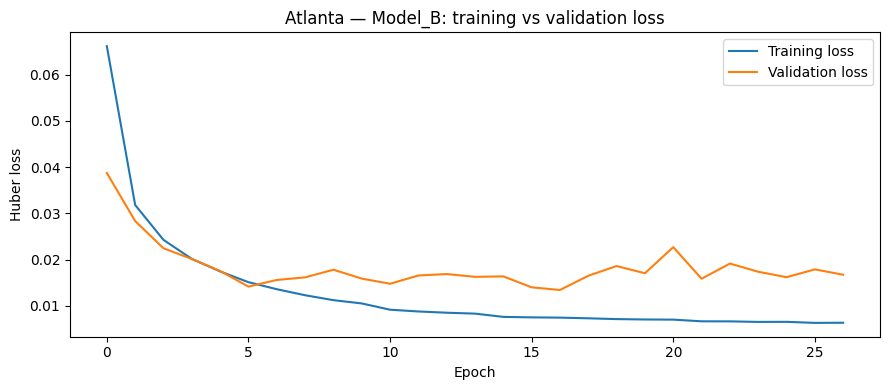

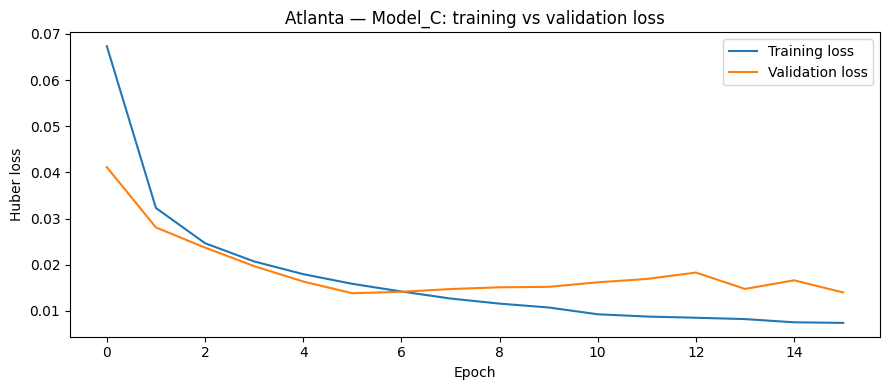

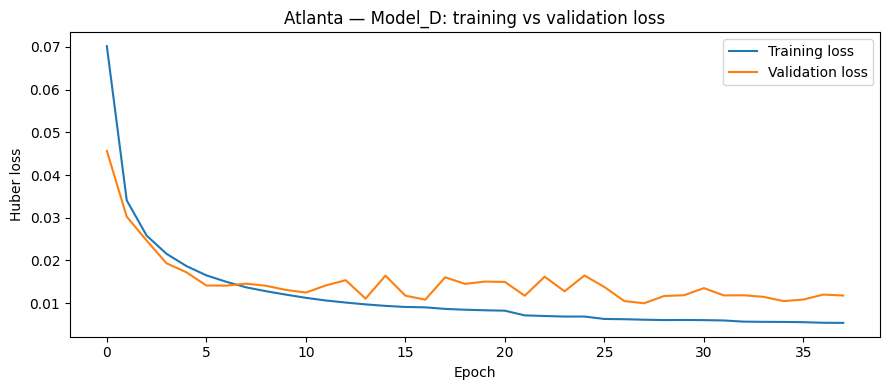

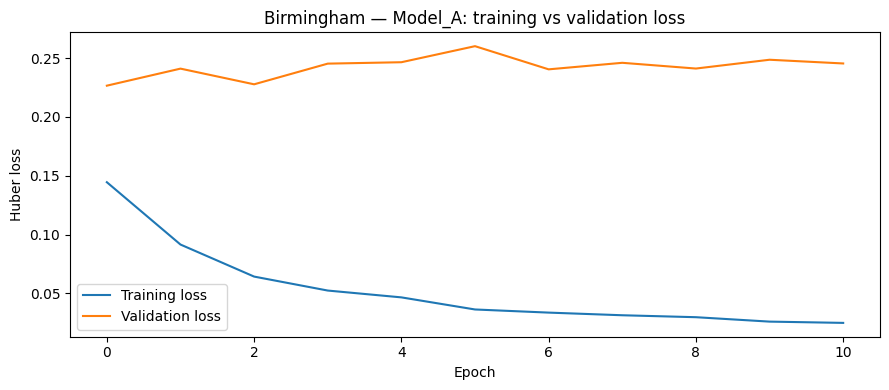

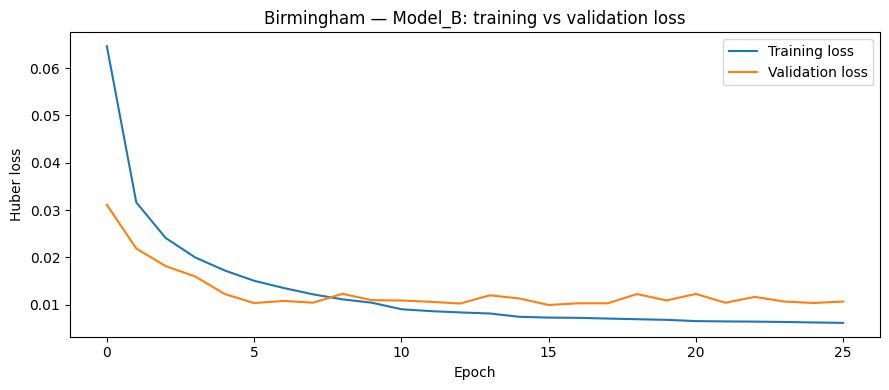

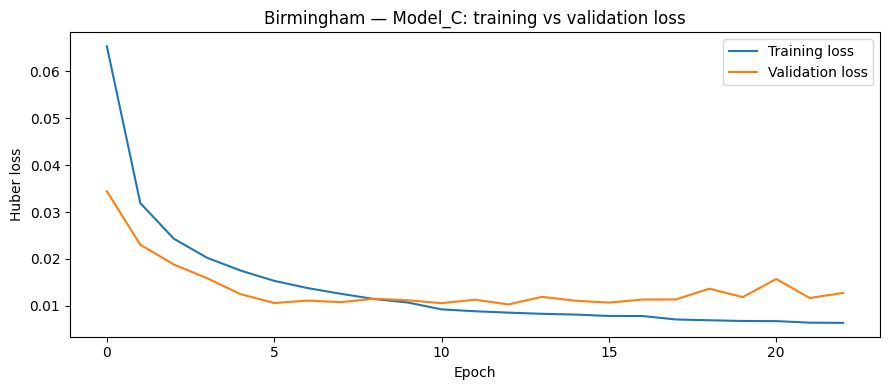

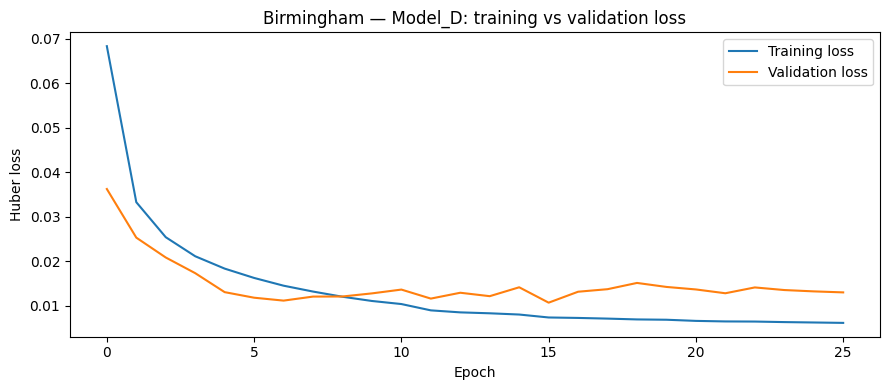

In [16]:
for city in CITIES:
    for model_name in MODEL_NAMES:
        history_path = (
            RESULTS_DIR
            / city.lower()
            / model_name.lower()
            / "history.csv"
        )

        history = pd.read_csv(history_path)

        plt.figure(figsize=(9, 4))
        plt.plot(
            history["loss"],
            label="Training loss",
        )
        plt.plot(
            history["val_loss"],
            label="Validation loss",
        )
        plt.title(
            f"{city} — {model_name}: training vs validation loss"
        )
        plt.xlabel("Epoch")
        plt.ylabel("Huber loss")
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            RESULTS_DIR
            / city.lower()
            / model_name.lower()
            / "learning_curve.png",
            dpi=150,
        )
        plt.show()


## 12. Final 2023 comparison

The 2023 test set is the final out-of-sample evaluation. Early stopping uses validation loss from 2022 only.


In [17]:
test_results = metrics_table[
    metrics_table["Split"] == "test"
].copy()

for city in CITIES:
    city_table = test_results[
        test_results["City"] == city
    ].sort_values(
        "R2",
        ascending=False,
    )

    print(f"\n{city} — final 2023 ranking")
    display(
        city_table[
            [
                "Model",
                "R2",
                "MAE_MW",
                "RMSE_MW",
                "MAPE_percent",
                "WAPE_percent",
            ]
        ]
    )



Atlanta — final 2023 ranking


,Model,R2,MAE_MW,RMSE_MW,MAPE_percent,WAPE_percent
9,Model_D,0.986639,29.087891,37.635212,1.819388,1.829716
7,Model_C,0.981303,33.303224,44.521722,2.067216,2.094873
5,Model_B,0.981283,32.541016,44.545689,1.953273,2.046928
3,Model_A,0.694690,131.663606,179.909179,8.099629,8.282039
1,Baseline_0,0.267117,219.142828,278.740639,13.097927,13.784746



Birmingham — final 2023 ranking


,Model,R2,MAE_MW,RMSE_MW,MAPE_percent,WAPE_percent
17,Model_C,0.983688,23.769770,32.626588,1.804409,1.890087
15,Model_B,0.982000,25.423069,34.273197,1.986802,2.021551
19,Model_D,0.980433,24.870328,35.733391,1.858396,1.977599
13,Model_A,0.594047,128.839695,162.762198,10.316311,10.244870
11,Baseline_0,0.178940,198.490026,231.474455,16.190939,15.783214


## 13. Actual vs predicted plots for the best LSTM


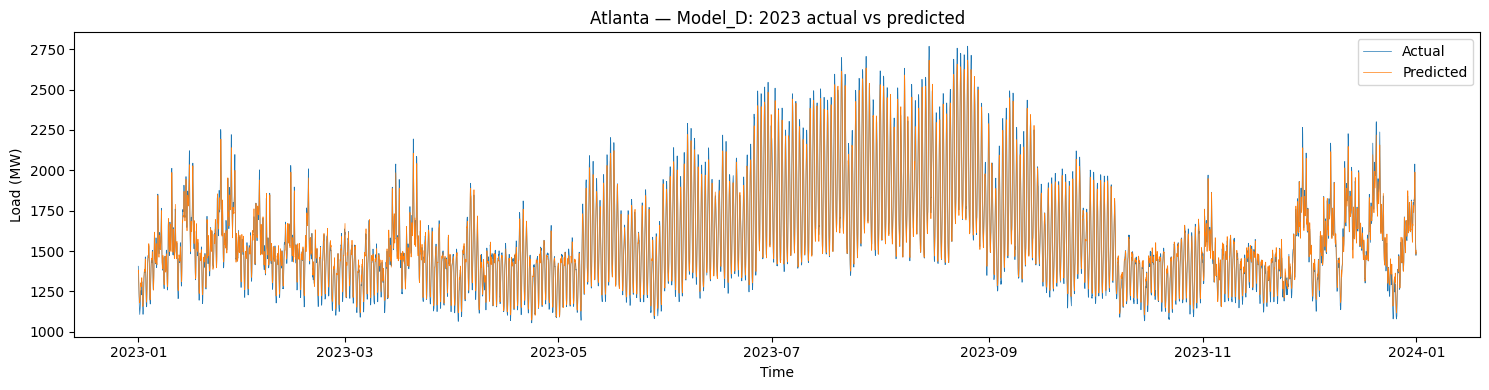

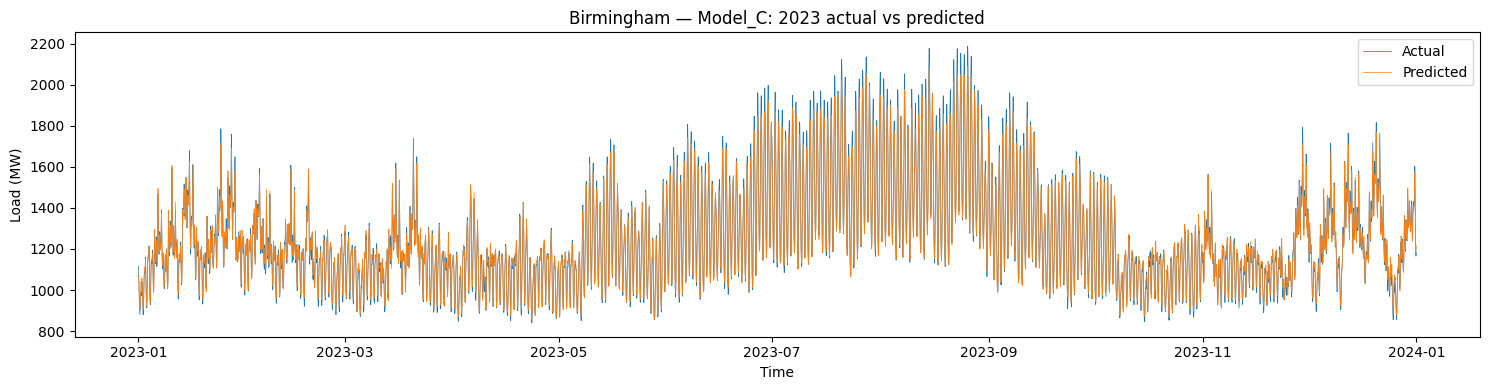

In [18]:
for city in CITIES:
    city_test = test_results[
        (test_results["City"] == city)
        & (test_results["Model"] != "Baseline_0")
    ]

    best_name = city_test.sort_values(
        "R2",
        ascending=False,
    ).iloc[0]["Model"]

    pred_path = (
        RESULTS_DIR
        / city.lower()
        / best_name.lower()
        / "test_predictions.csv"
    )

    pred = pd.read_csv(
        pred_path,
        parse_dates=["target_timestamp"],
    )

    plt.figure(figsize=(15, 4))
    plt.plot(
        pred["target_timestamp"],
        pred["actual_load_mw"],
        linewidth=0.5,
        label="Actual",
    )
    plt.plot(
        pred["target_timestamp"],
        pred["predicted_load_mw"],
        linewidth=0.5,
        label="Predicted",
    )
    plt.title(
        f"{city} — {best_name}: 2023 actual vs predicted"
    )
    plt.xlabel("Time")
    plt.ylabel("Load (MW)")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR
        / city.lower()
        / f"{best_name.lower()}_2023_actual_vs_predicted.png",
        dpi=150,
    )
    plt.show()


## 14. Save the exact training configuration


In [19]:
training_config = {
    "seed": SEED,
    "lookback_hours": LOOKBACK_HOURS,
    "horizon_hours": HORIZON_HOURS,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "architecture": [
        "LSTM(64, return_sequences=True, L2=1e-4)",
        "Dropout(0.25)",
        "LSTM(32, return_sequences=False, L2=1e-4)",
        "Dropout(0.25)",
        "Dense(16, ReLU, L2=1e-4)",
        "Dense(1, Linear)",
    ],
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "loss": "Huber(delta=1.0)",
    "dropout": DROPOUT,
    "l2": L2_REG,
    "early_stopping": {
        "monitor": "val_loss",
        "patience": EARLY_STOPPING_PATIENCE,
        "restore_best_weights": True,
    },
    "reduce_lr": {
        "monitor": "val_loss",
        "factor": LR_FACTOR,
        "patience": LR_PATIENCE,
        "min_lr": MIN_LR,
    },
    "split": {
        "train": "2016–2021",
        "validation": "2022",
        "test": "2023",
    },
    "models": {
        "Baseline_0": "historical hour × weekday mean, training period only",
        "Model_A": 31,
        "Model_B": 43,
        "Model_C": 44,
        "Model_D": 51,
    },
}

(RESULTS_DIR / "training_config.json").write_text(
    json.dumps(training_config, indent=2),
    encoding="utf-8",
)

print("Saved:", RESULTS_DIR / "training_config.json")


Saved: d:\Downloads\BTP\model_training\lstm_training_2\LSTM_GPU_TRAINING\LSTM_DATA_PREP\training_results\training_config.json


## 15. Output structure

After a successful run:

```text
training_results/
├── training_config.json
├── all_model_metrics.csv
├── atlanta/
│   ├── baseline_0/
│   ├── model_a/
│   ├── model_b/
│   ├── model_c/
│   └── model_d/
└── birmingham/
    ├── baseline_0/
    ├── model_a/
    ├── model_b/
    ├── model_c/
    └── model_d/
```

Each LSTM directory contains the saved `.keras` model, training history, learning curve, and validation/test predictions.

The previous LSTM benchmark can be added afterward as a reference row. It is not used for training or model selection in this notebook.
